##NAME: Vedangi Eknath Patil
##PRN: 202401040058
##Div: A
##Batch: A1
##Roll No: 19

# Practical Assignment No. 3
## Performance Evaluation of Regression Models
### Topic: Crop Yield Prediction Using Regression Models

**Aim:** To develop regression models for a real-world agricultural application, evaluate their performance using suitable metrics, and implement/analyze Gradient Descent for Linear Regression.

**Application:** Estimate crop yield from agricultural measurements such as fertilizer usage, temperature, and soil nutrients.

**Target variable:** Crop yield (the dataset may name this column `yeild`).

**Dataset:** `Crop_Yield_Soil_Weather.csv`  
Dataset page: [Crop Yield Prediction Using Soil and Weather](https://www.kaggle.com/datasets/gurudathg/crop-yield-prediction-using-soil-and-weather)

## 1 — Dataset basics and information

This section displays the first and last rows, dataset dimensions, column names, data types, statistical summary, unique values, and memory usage.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset in Google Colab.
# If the file is not already in /content, upload it when prompted.
from pathlib import Path

file_path = Path("/content/Crop_Yield_Soil_Weather.csv")

if not file_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            file_path = Path(next(iter(uploaded.keys())))
    except ImportError:
        file_path = Path("Crop_Yield_Soil_Weather.csv")

df = pd.read_csv(file_path)

# Clean accidental spaces in column names.
df.columns = df.columns.str.strip()

# Standardize the target column name, because this dataset may spell it "yeild".
target_candidates = ["yield", "yeild", "crop_yield", "Crop_Yield", "Yield"]
target_col = next((c for c in df.columns if c.lower() in [x.lower() for x in target_candidates]), None)

if target_col is None:
    raise ValueError(
        "Could not identify the crop-yield target column. "
        f"Available columns: {df.columns.tolist()}"
    )

df = df.rename(columns={target_col: "Yield"})
target_col = "Yield"

print("=" * 60)
print("1. DATASET OVERVIEW")
print("=" * 60)

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nNumber of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nNumber of unique values in each column:")
print(df.nunique())

print("\nDataset memory usage:")
print(f"{df.memory_usage(deep=True).sum() / 1024:.2f} KB")

Saving Crop Yiled with Soil and Weather.csv to Crop Yiled with Soil and Weather.csv
1. DATASET OVERVIEW

First 5 rows:


,Fertilizer,temp,N,P,K,Yield
0,80.0,28.0,80.0,24.0,20.0,12.0
1,77.0,27.0,78.0,23.0,20.0,12.0
2,80.0,26.0,80.0,24.0,20.0,12.0
3,80.0,28.0,80.0,24.0,20.0,12.0
4,78.0,27.0,78.0,23.0,19.0,12.0



Last 5 rows:


,Fertilizer,temp,N,P,K,Yield
2591,78.942684,27.014634,76.838312,23.087606,20.044206,10.348503
2592,79.077362,27.153127,76.927657,23.068234,20.155436,10.528122
2593,78.986271,28.108948,77.164352,22.863654,20.989871,10.564205
2594,78.894767,28.141344,76.925149,23.071553,20.873662,10.442511
2595,79.050307,26.980865,77.124758,23.050197,19.960695,10.584638



Number of rows and columns:
(2596, 6)

Column names:
['Fertilizer', 'temp', 'N', 'P', 'K', 'Yield']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2596 entries, 0 to 2595
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Fertilizer  2596 non-null   float64
 1   temp        2596 non-null   float64
 2   N           2596 non-null   float64
 3   P           2596 non-null   float64
 4   K           2596 non-null   float64
 5   Yield       2596 non-null   float64
dtypes: float64(6)
memory usage: 121.8 KB

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Fertilizer,2596.0,66.487433,9.747669,49.751436,59.865423,65.011969,76.943112,80.223893
temp,2596.0,33.848237,5.371279,23.771310,28.000000,36.965121,38.928914,40.272480
N,2596.0,69.522900,6.802806,58.839466,64.834635,69.894076,76.845919,80.218705
P,2596.0,20.708194,1.973419,17.723223,18.988224,20.889579,22.125618,25.162178
K,2596.0,17.806268,1.940037,14.704883,15.975932,18.061975,19.133858,22.064666
Yield,2596.0,8.533832,1.938789,5.150745,6.929404,8.501720,10.045179,12.337651



Number of unique values in each column:
Fertilizer    2520
temp          2514
N             2522
P             2509
K             2509
Yield         2514
dtype: int64

Dataset memory usage:
121.82 KB


## 2 — Explore the data before preprocessing

Check missing values, duplicate rows, data types, and the distribution of the target variable. These checks help identify data-quality issues before training models.

In [ ]:
print("=" * 60)
print("2. DATA QUALITY CHECK")
print("=" * 60)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nUnique values in categorical columns:")
categorical_cols = df.select_dtypes(include=["object", "category"]).columns
if len(categorical_cols) == 0:
    print("No categorical columns found in this dataset.")
else:
    for col in categorical_cols:
        print(f"\n{col}:")
        print(df[col].value_counts(dropna=False))

print("\nCrop yield summary:")
print(df[target_col].describe())

2. DATA QUALITY CHECK

Missing values in each column:
Fertilizer    0
temp          0
N             0
P             0
K             0
Yield         0
dtype: int64

Total missing values:
0

Number of duplicate rows:
11

Data types:
Fertilizer    float64
temp          float64
N             float64
P             float64
K             float64
Yield         float64
dtype: object

Unique values in categorical columns:
No categorical columns found in this dataset.

Crop yield summary:
count    2596.000000
mean        8.533832
std         1.938789
min         5.150745
25%         6.929404
50%         8.501720
75%        10.045179
max        12.337651
Name: Yield, dtype: float64


### Preprocessing

For the regression models below, use numerical input features. Missing numerical values are filled with the median, and duplicate rows are removed. If the dataset contains categorical columns, this notebook keeps them out of the numeric regression features rather than silently converting category names to arbitrary numbers.

In [ ]:
# Remove duplicate rows and create a clean working dataframe.
df = df.drop_duplicates().copy()

# Convert numeric-looking columns to numeric where possible.
for col in df.columns:
    if df[col].dtype == "object":
        converted = pd.to_numeric(df[col], errors="coerce")
        # Convert only when most non-missing values are numeric.
        if converted.notna().sum() >= 0.8 * df[col].notna().sum():
            df[col] = converted

# Select numerical columns and impute missing values with the median.
numeric_df = df.select_dtypes(include=np.number).copy()

if target_col not in numeric_df.columns:
    raise ValueError("The Yield target must be numeric. Check the dataset's target column.")

numeric_df = numeric_df.replace([np.inf, -np.inf], np.nan)
numeric_df = numeric_df.dropna(subset=[target_col])
numeric_df = numeric_df.fillna(numeric_df.median(numeric_only=True))

# Remove constant input columns because they cannot explain variation.
feature_cols = [
    col for col in numeric_df.columns
    if col != target_col and numeric_df[col].nunique() > 1
]

if len(feature_cols) < 2:
    raise ValueError(
        "At least two varying numeric input features are needed for this assignment. "
        f"Detected features: {feature_cols}"
    )

model_df = numeric_df[feature_cols + [target_col]].copy()

print("Shape after cleaning:", model_df.shape)
print("Numerical input features:", feature_cols)
print("Target variable:", target_col)
display(model_df.head())

Shape after cleaning: (2585, 6)
Numerical input features: ['Fertilizer', 'temp', 'N', 'P', 'K']
Target variable: Yield


,Fertilizer,temp,N,P,K,Yield
0,80.0,28.0,80.0,24.0,20.0,12.0
1,77.0,27.0,78.0,23.0,20.0,12.0
2,80.0,26.0,80.0,24.0,20.0,12.0
4,78.0,27.0,78.0,23.0,19.0,12.0
6,75.0,26.0,75.0,22.0,19.0,12.0


## 3 — Visualize the dataset

The following plots show the target distribution, individual feature distributions, relationships between inputs and crop yield, and correlations among numerical variables.

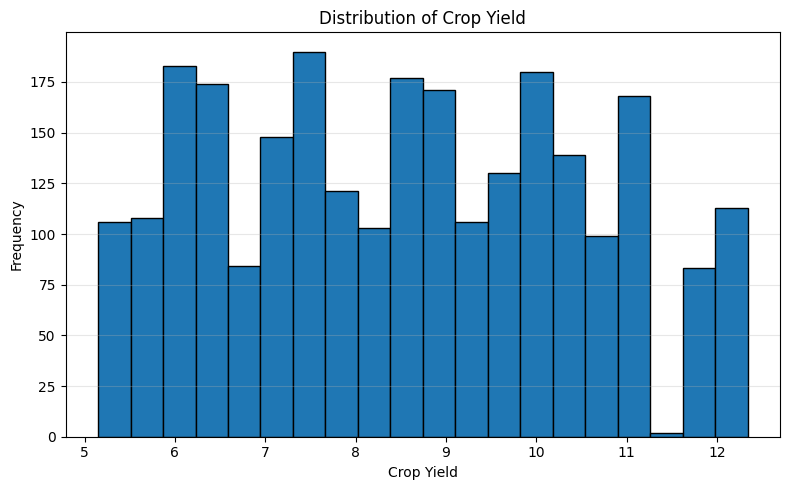

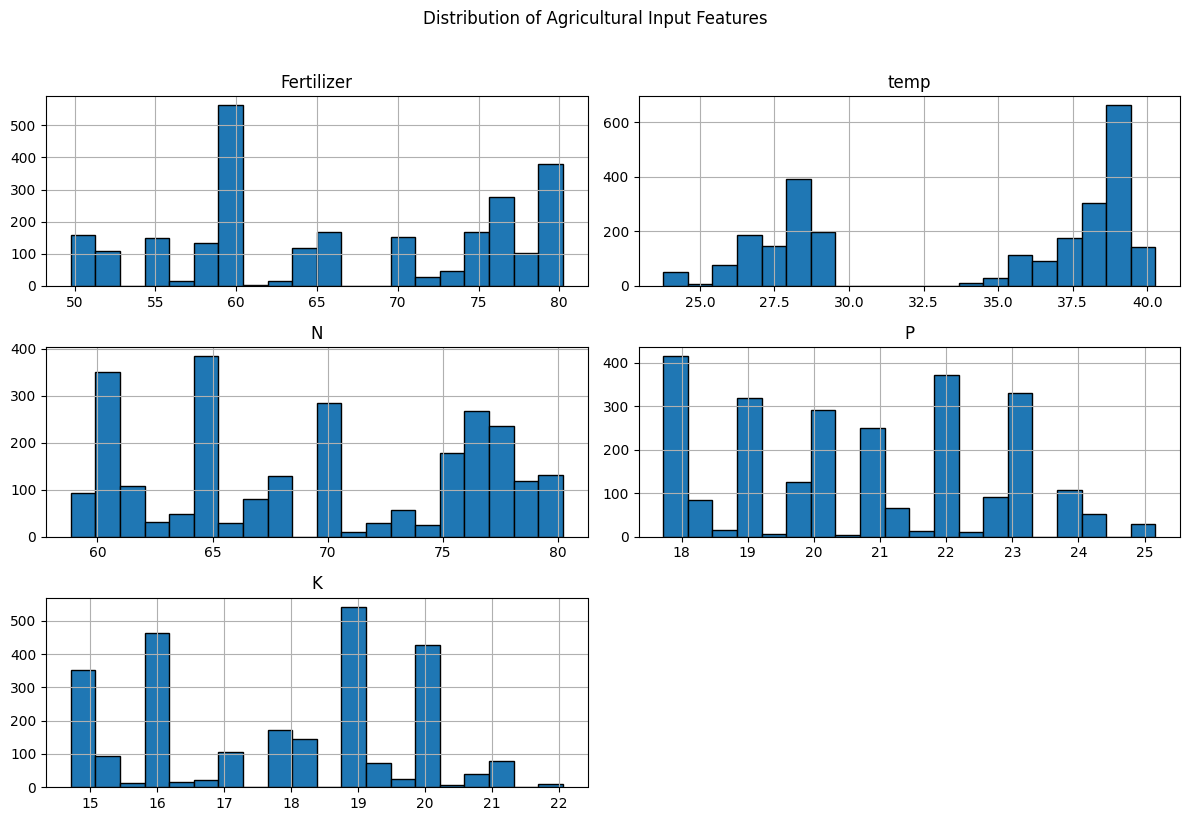

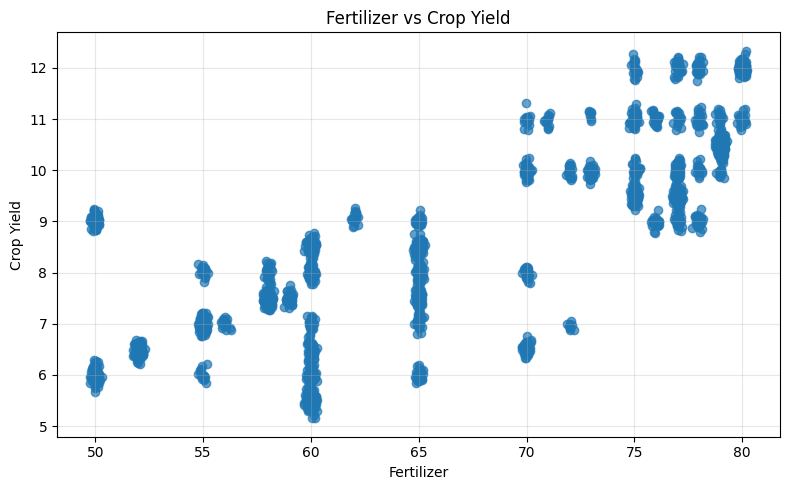

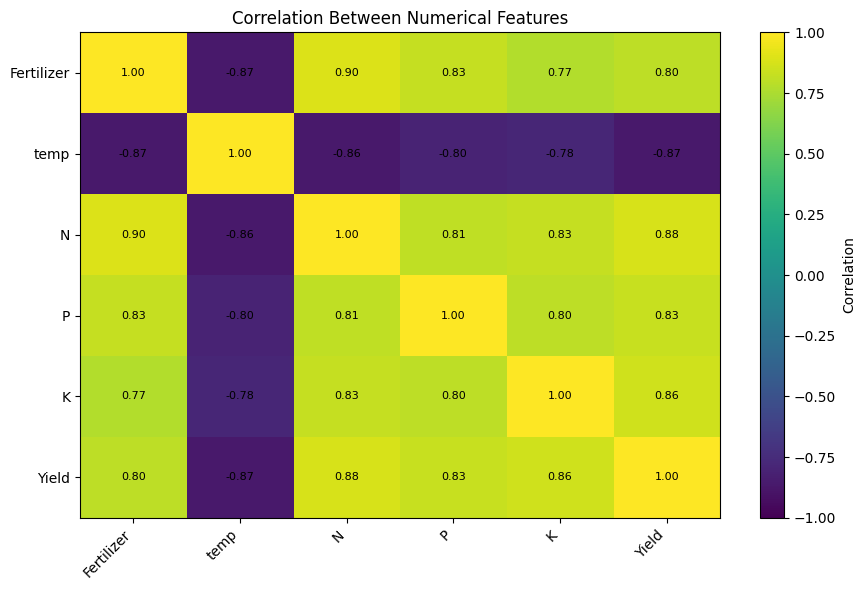

In [ ]:
# Graph 1: Distribution of crop yield
plt.figure(figsize=(8, 5))
plt.hist(model_df[target_col], bins=20, edgecolor="black")
plt.xlabel("Crop Yield")
plt.ylabel("Frequency")
plt.title("Distribution of Crop Yield")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: Histograms of numeric input features
model_df[feature_cols].hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distribution of Agricultural Input Features", y=1.02)
plt.tight_layout()
plt.show()

# Graph 3: First input feature vs crop yield
simple_feature = feature_cols[0]
plt.figure(figsize=(8, 5))
plt.scatter(model_df[simple_feature], model_df[target_col], alpha=0.7)
plt.xlabel(simple_feature)
plt.ylabel("Crop Yield")
plt.title(f"{simple_feature} vs Crop Yield")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 4: Correlation heatmap using Matplotlib
corr = model_df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

# Part 1 — Simple Linear Regression: With and Without Library

## 1. Aim
Implement Simple Linear Regression using scikit-learn and manually using the least-squares formulas. Compare the models using MSE, RMSE, MAE, and R².

## 2. Theory
Simple Linear Regression predicts a continuous value using one independent variable.

\[
\hat{y} = b_0 + b_1x
\]

- \(x\): one agricultural feature
- \(\hat{y}\): predicted crop yield
- \(b_0\): intercept
- \(b_1\): slope


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_simple = model_df[[simple_feature]].copy()
y = model_df[target_col].copy()

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.20, random_state=42
)

print("Simple regression input feature:", simple_feature)
print("Training rows:", len(X_train_s))
print("Testing rows:", len(X_test_s))

Simple regression input feature: Fertilizer
Training rows: 2068
Testing rows: 517


## 3. Implementation 1 — Simple Linear Regression using a library


SIMPLE LINEAR REGRESSION WITH LIBRARY
-------------------------------------
Intercept: -2.0221251910268094
Slope: 0.15860630565815823
MSE: 1.4250
RMSE: 1.1937
MAE: 0.9096
R2: 0.6176


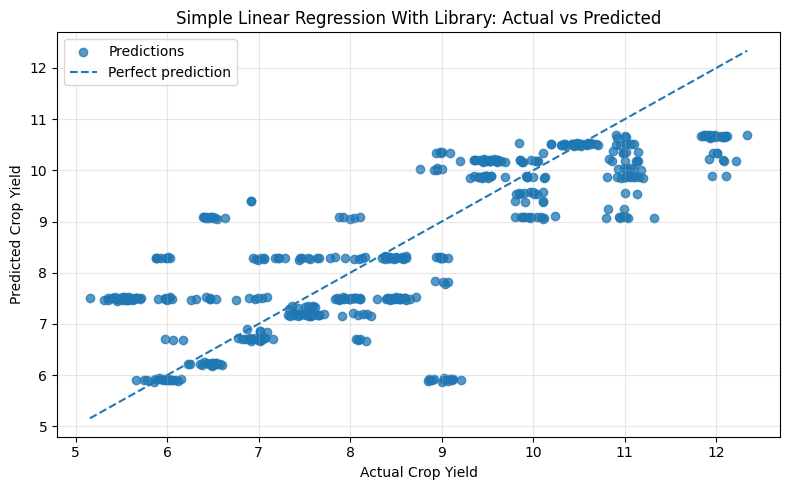

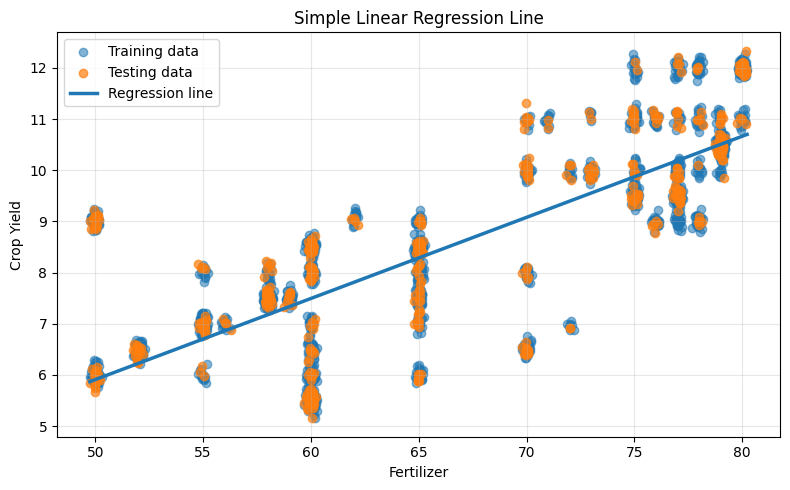

In [ ]:
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)
y_pred_simple_lib = simple_model.predict(X_test_s)

simple_lib_metrics = {
    "MSE": mean_squared_error(y_test_s, y_pred_simple_lib),
    "RMSE": np.sqrt(mean_squared_error(y_test_s, y_pred_simple_lib)),
    "MAE": mean_absolute_error(y_test_s, y_pred_simple_lib),
    "R2": r2_score(y_test_s, y_pred_simple_lib)
}

print("\nSIMPLE LINEAR REGRESSION WITH LIBRARY")
print("-------------------------------------")
print("Intercept:", simple_model.intercept_)
print("Slope:", simple_model.coef_[0])
for metric, value in simple_lib_metrics.items():
    print(f"{metric}: {value:.4f}")

# Graph 1: Actual vs predicted
plt.figure(figsize=(8, 5))
plt.scatter(y_test_s, y_pred_simple_lib, alpha=0.75, label="Predictions")
low = min(y_test_s.min(), y_pred_simple_lib.min())
high = max(y_test_s.max(), y_pred_simple_lib.max())
plt.plot([low, high], [low, high], "--", label="Perfect prediction")
plt.xlabel("Actual Crop Yield")
plt.ylabel("Predicted Crop Yield")
plt.title("Simple Linear Regression With Library: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: Regression line
x_line = np.linspace(X_simple[simple_feature].min(), X_simple[simple_feature].max(), 200)
y_line = simple_model.predict(pd.DataFrame({simple_feature: x_line}))
plt.figure(figsize=(8, 5))
plt.scatter(X_train_s[simple_feature], y_train_s, alpha=0.55, label="Training data")
plt.scatter(X_test_s[simple_feature], y_test_s, alpha=0.7, label="Testing data")
plt.plot(x_line, y_line, linewidth=2.5, label="Regression line")
plt.xlabel(simple_feature)
plt.ylabel("Crop Yield")
plt.title("Simple Linear Regression Line")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Implementation 2 — Simple Linear Regression without a regression library

The slope and intercept are calculated directly using the least-squares formulas. NumPy is used for calculations, but scikit-learn's regression estimator is not used.


SIMPLE LINEAR REGRESSION WITHOUT LIBRARY
----------------------------------------
Intercept: -2.022125191026804
Slope: 0.15860630565815814
MSE: 1.4250
RMSE: 1.1937
MAE: 0.9096
R2: 0.6176


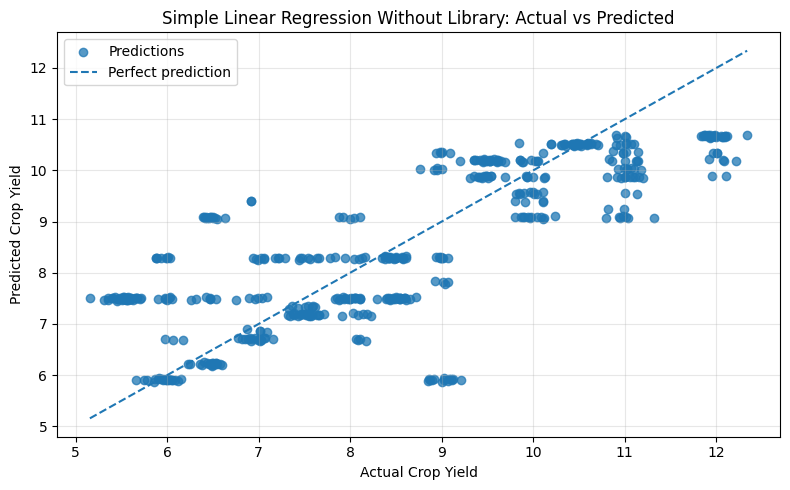

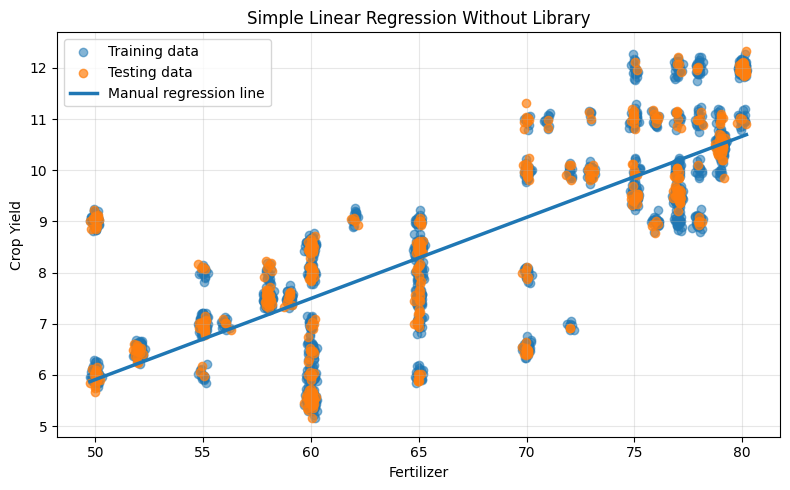

In [ ]:
x_train = X_train_s[simple_feature].to_numpy(dtype=float)
x_test = X_test_s[simple_feature].to_numpy(dtype=float)
y_train_arr = y_train_s.to_numpy(dtype=float)
y_test_arr = y_test_s.to_numpy(dtype=float)

x_mean = np.mean(x_train)
y_mean = np.mean(y_train_arr)

numerator = np.sum((x_train - x_mean) * (y_train_arr - y_mean))
denominator = np.sum((x_train - x_mean) ** 2)

if denominator == 0:
    raise ValueError("The selected input feature has no variation in the training set.")

slope_manual = numerator / denominator
intercept_manual = y_mean - slope_manual * x_mean
y_pred_simple_manual = intercept_manual + slope_manual * x_test

simple_manual_metrics = {
    "MSE": mean_squared_error(y_test_arr, y_pred_simple_manual),
    "RMSE": np.sqrt(mean_squared_error(y_test_arr, y_pred_simple_manual)),
    "MAE": mean_absolute_error(y_test_arr, y_pred_simple_manual),
    "R2": r2_score(y_test_arr, y_pred_simple_manual)
}

print("\nSIMPLE LINEAR REGRESSION WITHOUT LIBRARY")
print("----------------------------------------")
print("Intercept:", intercept_manual)
print("Slope:", slope_manual)
for metric, value in simple_manual_metrics.items():
    print(f"{metric}: {value:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(y_test_arr, y_pred_simple_manual, alpha=0.75, label="Predictions")
low = min(y_test_arr.min(), y_pred_simple_manual.min())
high = max(y_test_arr.max(), y_pred_simple_manual.max())
plt.plot([low, high], [low, high], "--", label="Perfect prediction")
plt.xlabel("Actual Crop Yield")
plt.ylabel("Predicted Crop Yield")
plt.title("Simple Linear Regression Without Library: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

x_line_manual = np.linspace(x_train.min(), x_test.max(), 200)
y_line_manual = intercept_manual + slope_manual * x_line_manual
plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train_arr, alpha=0.55, label="Training data")
plt.scatter(x_test, y_test_arr, alpha=0.7, label="Testing data")
plt.plot(x_line_manual, y_line_manual, linewidth=2.5, label="Manual regression line")
plt.xlabel(simple_feature)
plt.ylabel("Crop Yield")
plt.title("Simple Linear Regression Without Library")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Evaluation metrics and comparative analysis

- **MSE:** Mean Squared Error; lower is better.
- **RMSE:** Root Mean Squared Error; lower is better and uses the target's units.
- **MAE:** Mean Absolute Error; lower is better.
- **R²:** Coefficient of determination; closer to 1 is generally better.

Simple Linear Regression — Comparative Results


,Without Library,With Library
MSE,1.4250,1.4250
RMSE,1.1937,1.1937
MAE,0.9096,0.9096
R2,0.6176,0.6176


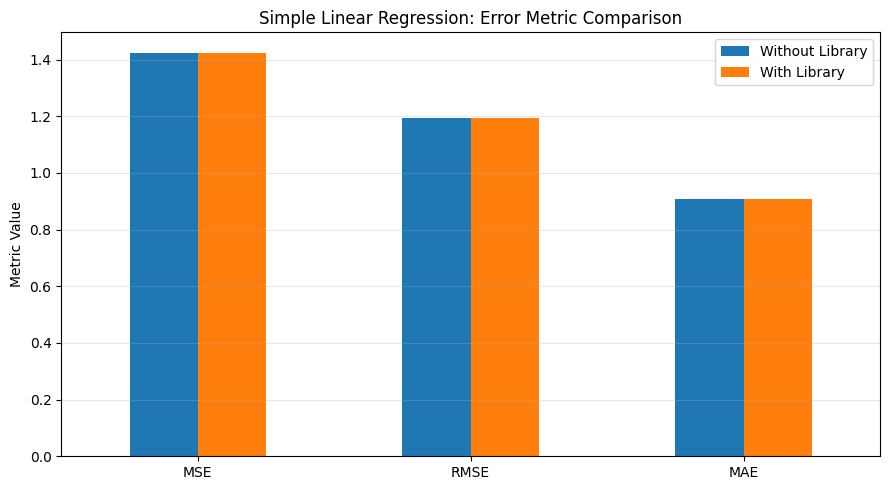

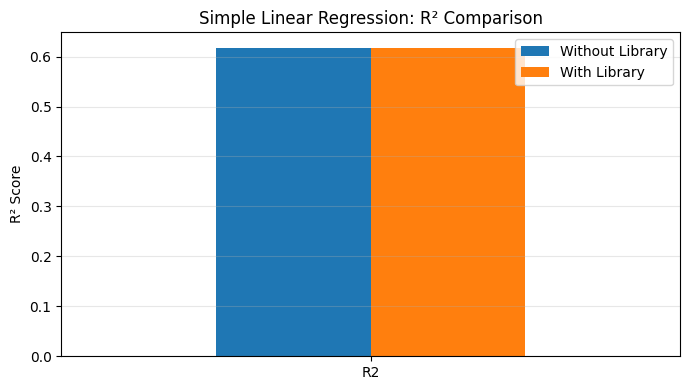

In [ ]:
simple_comparison = pd.DataFrame({
    "Without Library": simple_manual_metrics,
    "With Library": simple_lib_metrics
})
print("Simple Linear Regression — Comparative Results")
display(simple_comparison.round(4))

simple_comparison.loc[["MSE", "RMSE", "MAE"]].plot(kind="bar", figsize=(9, 5))
plt.title("Simple Linear Regression: Error Metric Comparison")
plt.ylabel("Metric Value")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

simple_comparison.loc[["R2"]].plot(kind="bar", figsize=(7, 4))
plt.title("Simple Linear Regression: R² Comparison")
plt.ylabel("R² Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Part 2 — Multiple Linear Regression: With Library and From Scratch Using Gradient Descent

## 1. Aim
Implement Multiple Linear Regression using scikit-learn and manually using Gradient Descent, then compare the evaluation metrics.

## 2. Theory
Multiple Linear Regression predicts a continuous target using two or more input features.

\[
\hat{y} = b + w_1x_1 + w_2x_2 + \cdots + w_nx_n
\]

Gradient Descent updates the weights and bias iteratively to reduce the Mean Squared Error cost. Input features are standardized for the manual Gradient Descent implementation to help it converge.

In [ ]:
# Use all numerical input features, excluding the target.
X_multi = model_df[feature_cols].copy()
y_multi = model_df[target_col].copy()

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.20, random_state=42
)

print("Features used:", feature_cols)
print("Training shape:", X_train_m.shape)
print("Testing shape:", X_test_m.shape)

Features used: ['Fertilizer', 'temp', 'N', 'P', 'K']
Training shape: (2068, 5)
Testing shape: (517, 5)


## 3. Implementation 1 — Multiple Linear Regression with library


MULTIPLE LINEAR REGRESSION WITH LIBRARY
---------------------------------------
Intercept: -0.7391725199183448
Coefficients: [-0.0504745  -0.12919654  0.11643209  0.20745254  0.25859317]
MSE: 0.4784
RMSE: 0.6917
MAE: 0.5720
R2: 0.8716


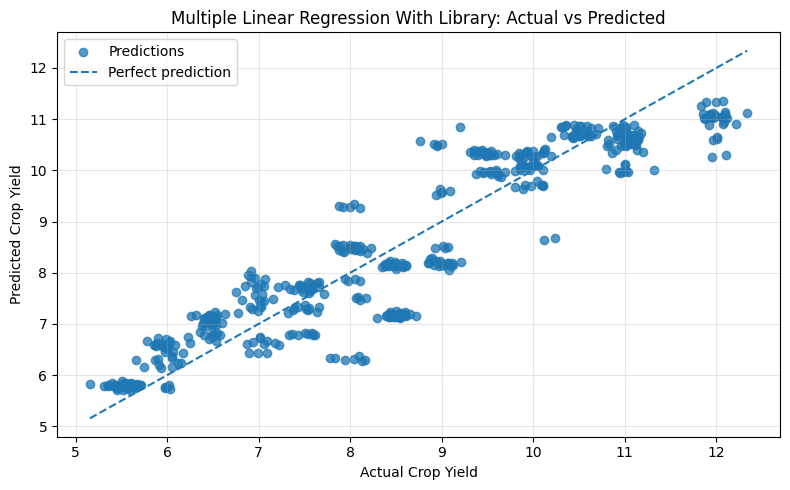

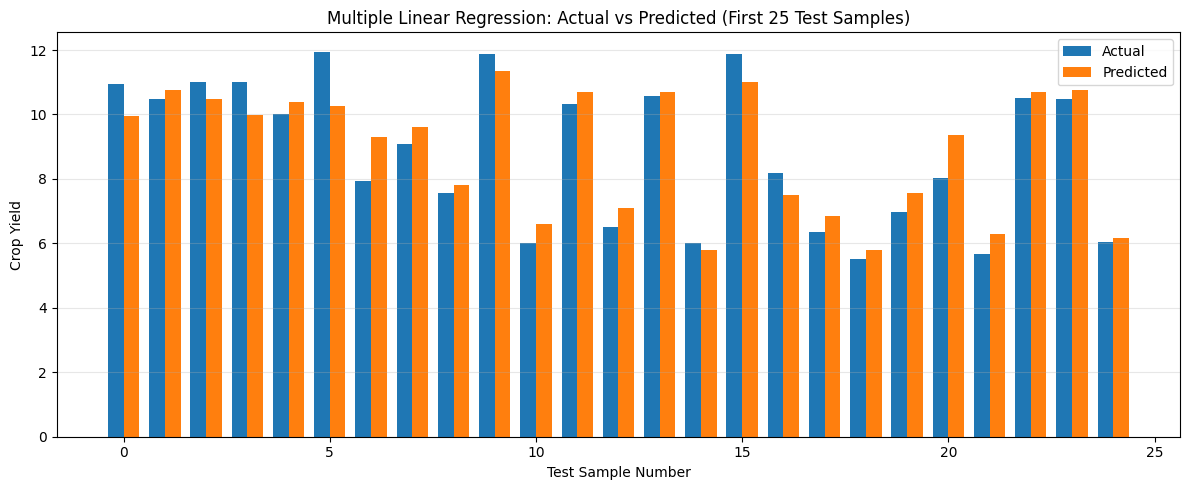

In [ ]:
multi_model = LinearRegression()
multi_model.fit(X_train_m, y_train_m)
y_pred_multi_lib = multi_model.predict(X_test_m)

multi_lib_metrics = {
    "MSE": mean_squared_error(y_test_m, y_pred_multi_lib),
    "RMSE": np.sqrt(mean_squared_error(y_test_m, y_pred_multi_lib)),
    "MAE": mean_absolute_error(y_test_m, y_pred_multi_lib),
    "R2": r2_score(y_test_m, y_pred_multi_lib)
}

print("\nMULTIPLE LINEAR REGRESSION WITH LIBRARY")
print("---------------------------------------")
print("Intercept:", multi_model.intercept_)
print("Coefficients:", multi_model.coef_)
for metric, value in multi_lib_metrics.items():
    print(f"{metric}: {value:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(y_test_m, y_pred_multi_lib, alpha=0.75, label="Predictions")
low = min(y_test_m.min(), y_pred_multi_lib.min())
high = max(y_test_m.max(), y_pred_multi_lib.max())
plt.plot([low, high], [low, high], "--", label="Perfect prediction")
plt.xlabel("Actual Crop Yield")
plt.ylabel("Predicted Crop Yield")
plt.title("Multiple Linear Regression With Library: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

comparison_multi_lib = pd.DataFrame({
    "Actual": y_test_m.to_numpy(),
    "Predicted": y_pred_multi_lib
}).head(25).reset_index(drop=True)

positions = np.arange(len(comparison_multi_lib))
width = 0.38
plt.figure(figsize=(12, 5))
plt.bar(positions - width / 2, comparison_multi_lib["Actual"], width, label="Actual")
plt.bar(positions + width / 2, comparison_multi_lib["Predicted"], width, label="Predicted")
plt.xlabel("Test Sample Number")
plt.ylabel("Crop Yield")
plt.title("Multiple Linear Regression: Actual vs Predicted (First 25 Test Samples)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Implementation 2 — Multiple Linear Regression from scratch using Gradient Descent

This implementation manually standardizes the features, initializes weights and bias, calculates predictions and gradients, updates the parameters, and records the training cost over epochs.


MULTIPLE LINEAR REGRESSION FROM SCRATCH USING GRADIENT DESCENT
---------------------------------------------------------------
Bias: 8.531913348843764
Weights: [-0.49379576 -0.69315537  0.79558178  0.41032894  0.50447672]
MSE: 0.4784
RMSE: 0.6917
MAE: 0.5720
R2: 0.8716


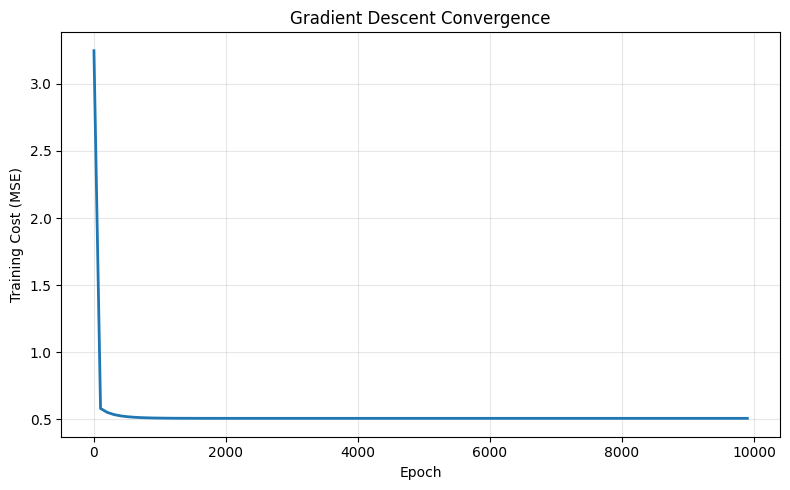

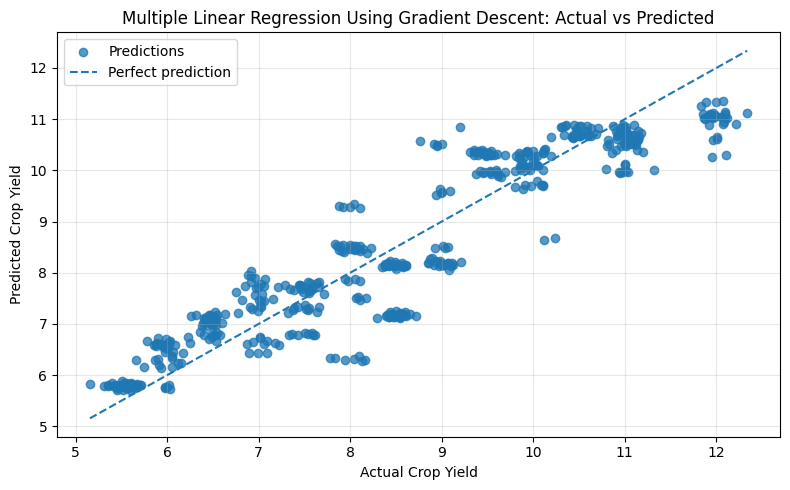

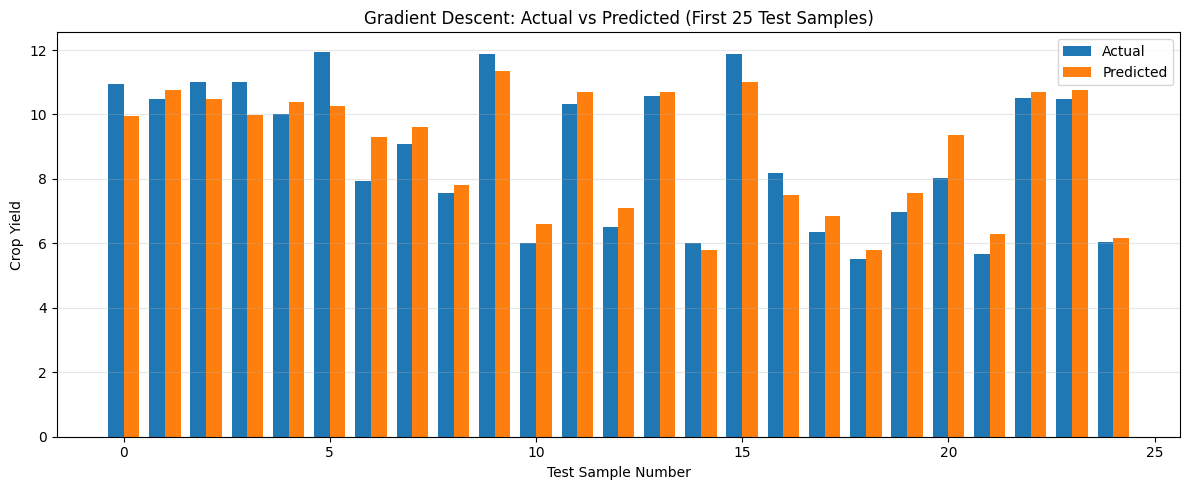

In [ ]:
# Convert the data to NumPy arrays.
X_train_arr = X_train_m.to_numpy(dtype=float)
X_test_arr = X_test_m.to_numpy(dtype=float)
y_train_arr_m = y_train_m.to_numpy(dtype=float)
y_test_arr_m = y_test_m.to_numpy(dtype=float)

# Standardize using training-set statistics only.
feature_mean = X_train_arr.mean(axis=0)
feature_std = X_train_arr.std(axis=0)
feature_std[feature_std == 0] = 1

X_train_scaled = (X_train_arr - feature_mean) / feature_std
X_test_scaled = (X_test_arr - feature_mean) / feature_std

# Initialize model parameters.
m, n = X_train_scaled.shape
weights = np.zeros(n)
bias = float(np.mean(y_train_arr_m))

learning_rate = 0.01
epochs = 10000
cost_history = []

# Batch Gradient Descent.
for epoch in range(epochs):
    y_train_pred = np.dot(X_train_scaled, weights) + bias
    errors = y_train_pred - y_train_arr_m

    dw = (2 / m) * np.dot(X_train_scaled.T, errors)
    db = (2 / m) * np.sum(errors)

    weights = weights - learning_rate * dw
    bias = bias - learning_rate * db

    if epoch % 100 == 0:
        current_pred = np.dot(X_train_scaled, weights) + bias
        cost_history.append(np.mean((current_pred - y_train_arr_m) ** 2))

# Predict test data.
y_pred_multi_gd = np.dot(X_test_scaled, weights) + bias

multi_gd_metrics = {
    "MSE": mean_squared_error(y_test_arr_m, y_pred_multi_gd),
    "RMSE": np.sqrt(mean_squared_error(y_test_arr_m, y_pred_multi_gd)),
    "MAE": mean_absolute_error(y_test_arr_m, y_pred_multi_gd),
    "R2": r2_score(y_test_arr_m, y_pred_multi_gd)
}

print("\nMULTIPLE LINEAR REGRESSION FROM SCRATCH USING GRADIENT DESCENT")
print("---------------------------------------------------------------")
print("Bias:", bias)
print("Weights:", weights)
for metric, value in multi_gd_metrics.items():
    print(f"{metric}: {value:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(np.arange(len(cost_history)) * 100, cost_history, linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Training Cost (MSE)")
plt.title("Gradient Descent Convergence")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(y_test_arr_m, y_pred_multi_gd, alpha=0.75, label="Predictions")
low = min(y_test_arr_m.min(), y_pred_multi_gd.min())
high = max(y_test_arr_m.max(), y_pred_multi_gd.max())
plt.plot([low, high], [low, high], "--", label="Perfect prediction")
plt.xlabel("Actual Crop Yield")
plt.ylabel("Predicted Crop Yield")
plt.title("Multiple Linear Regression Using Gradient Descent: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

comparison_multi_gd = pd.DataFrame({
    "Actual": y_test_arr_m,
    "Predicted": y_pred_multi_gd
}).head(25).reset_index(drop=True)

positions = np.arange(len(comparison_multi_gd))
plt.figure(figsize=(12, 5))
plt.bar(positions - width / 2, comparison_multi_gd["Actual"], width, label="Actual")
plt.bar(positions + width / 2, comparison_multi_gd["Predicted"], width, label="Predicted")
plt.xlabel("Test Sample Number")
plt.ylabel("Crop Yield")
plt.title("Gradient Descent: Actual vs Predicted (First 25 Test Samples)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Comparative analysis — Multiple Linear Regression

The library model uses scikit-learn's least-squares implementation. The from-scratch model uses iterative Gradient Descent, so its scores can be slightly different depending on learning rate and epochs.

Multiple Linear Regression — Comparative Results


,With Library,From Scratch (Gradient Descent)
MSE,0.4784,0.4784
RMSE,0.6917,0.6917
MAE,0.5720,0.5720
R2,0.8716,0.8716


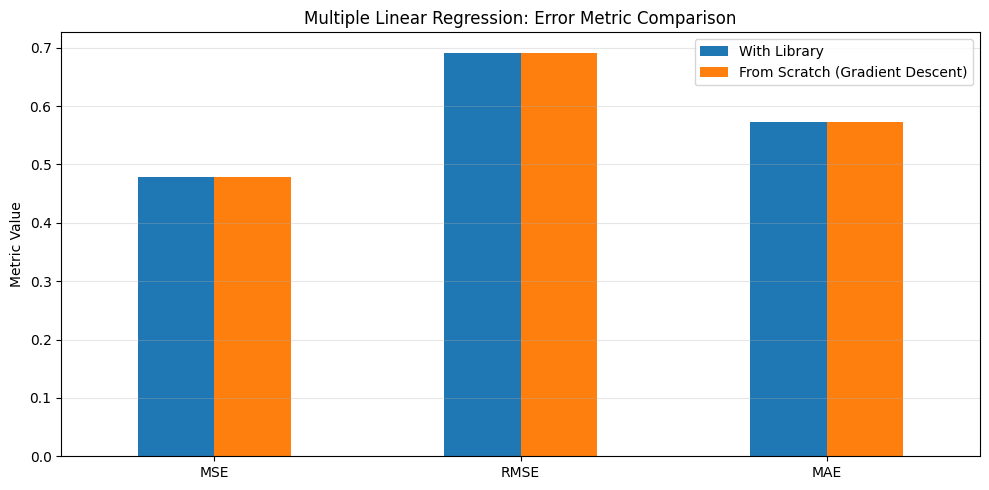

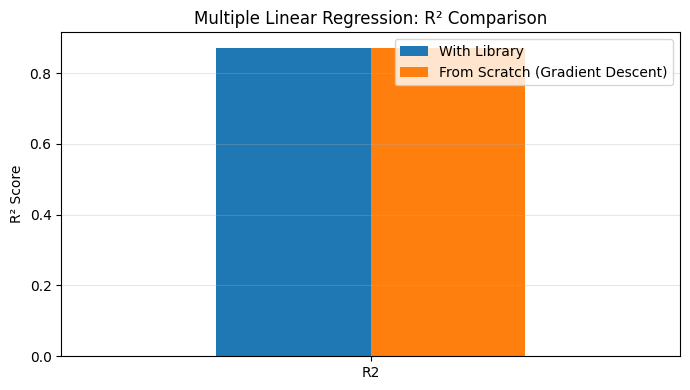

In [ ]:
multi_comparison = pd.DataFrame({
    "With Library": multi_lib_metrics,
    "From Scratch (Gradient Descent)": multi_gd_metrics
})
print("Multiple Linear Regression — Comparative Results")
display(multi_comparison.round(4))

multi_comparison.loc[["MSE", "RMSE", "MAE"]].plot(kind="bar", figsize=(10, 5))
plt.title("Multiple Linear Regression: Error Metric Comparison")
plt.ylabel("Metric Value")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

multi_comparison.loc[["R2"]].plot(kind="bar", figsize=(7, 4))
plt.title("Multiple Linear Regression: R² Comparison")
plt.ylabel("R² Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Part 3 — Polynomial Regression: With and Without Library

## 1. Aim
Implement degree-2 Polynomial Regression using scikit-learn and manually using NumPy, then compare MSE, RMSE, MAE, and R².

## 2. Theory
Polynomial Regression can represent a curved relationship between one input feature and the target.

\[
\hat{y} = b_0 + b_1x + b_2x^2
\]

For this section, the same single feature used in Simple Linear Regression is used to keep the comparison fair.

## 3. Implementation 1 — Polynomial Regression with library


POLYNOMIAL REGRESSION WITH LIBRARY
---------------------------------
Intercept: 26.22463388915383
Coefficients: [-0.71252854  0.00657013]
MSE: 1.2234
RMSE: 1.1061
MAE: 0.9416
R2: 0.6717


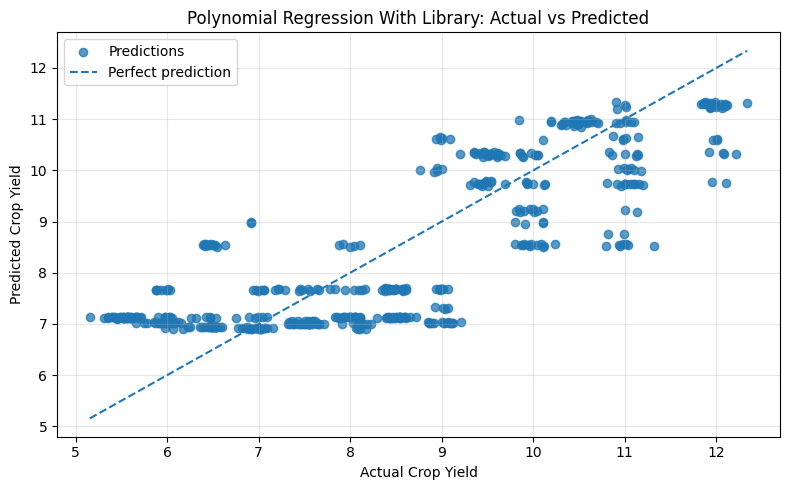

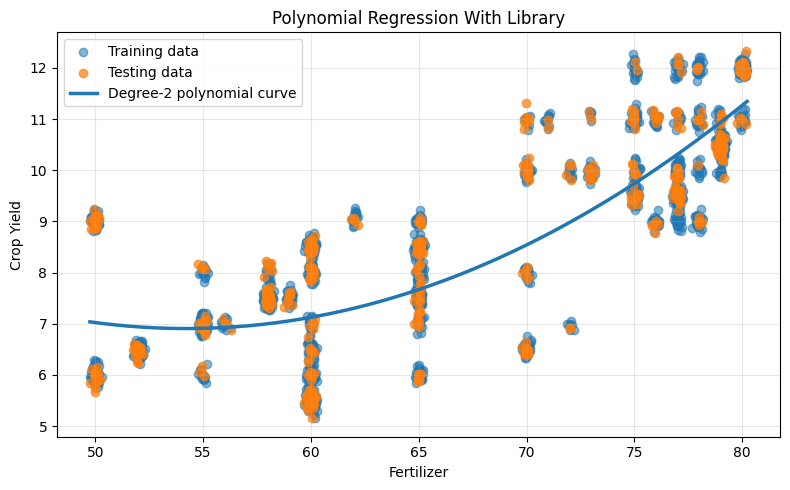

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_s)
X_test_poly = poly.transform(X_test_s)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train_s)
y_pred_poly_lib = poly_model.predict(X_test_poly)

poly_lib_metrics = {
    "MSE": mean_squared_error(y_test_s, y_pred_poly_lib),
    "RMSE": np.sqrt(mean_squared_error(y_test_s, y_pred_poly_lib)),
    "MAE": mean_absolute_error(y_test_s, y_pred_poly_lib),
    "R2": r2_score(y_test_s, y_pred_poly_lib)
}

print("\nPOLYNOMIAL REGRESSION WITH LIBRARY")
print("---------------------------------")
print("Intercept:", poly_model.intercept_)
print("Coefficients:", poly_model.coef_)
for metric, value in poly_lib_metrics.items():
    print(f"{metric}: {value:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(y_test_s, y_pred_poly_lib, alpha=0.75, label="Predictions")
low = min(y_test_s.min(), y_pred_poly_lib.min())
high = max(y_test_s.max(), y_pred_poly_lib.max())
plt.plot([low, high], [low, high], "--", label="Perfect prediction")
plt.xlabel("Actual Crop Yield")
plt.ylabel("Predicted Crop Yield")
plt.title("Polynomial Regression With Library: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

x_curve = np.linspace(X_simple[simple_feature].min(), X_simple[simple_feature].max(), 250)
x_curve_df = pd.DataFrame({simple_feature: x_curve})
y_curve = poly_model.predict(poly.transform(x_curve_df))

plt.figure(figsize=(8, 5))
plt.scatter(X_train_s[simple_feature], y_train_s, alpha=0.55, label="Training data")
plt.scatter(X_test_s[simple_feature], y_test_s, alpha=0.7, label="Testing data")
plt.plot(x_curve, y_curve, linewidth=2.5, label="Degree-2 polynomial curve")
plt.xlabel(simple_feature)
plt.ylabel("Crop Yield")
plt.title("Polynomial Regression With Library")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Implementation 2 — Polynomial Regression without a regression library

The polynomial features are created manually as \(x\) and \(x^2\). NumPy's least-squares function calculates the coefficients without using scikit-learn's regression estimator.


POLYNOMIAL REGRESSION WITHOUT LIBRARY
------------------------------------
Intercept: 26.22463388915361
Coefficient of x: -0.7125285443075624
Coefficient of x^2: 0.006570131712216654
MSE: 1.2234
RMSE: 1.1061
MAE: 0.9416
R2: 0.6717


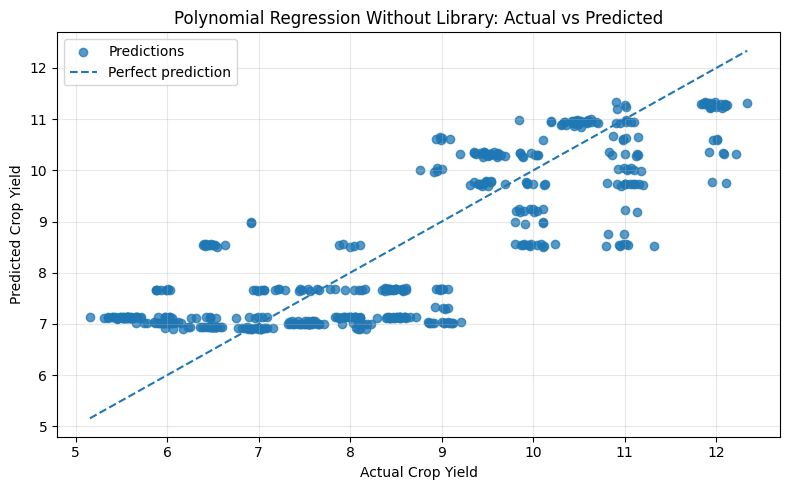

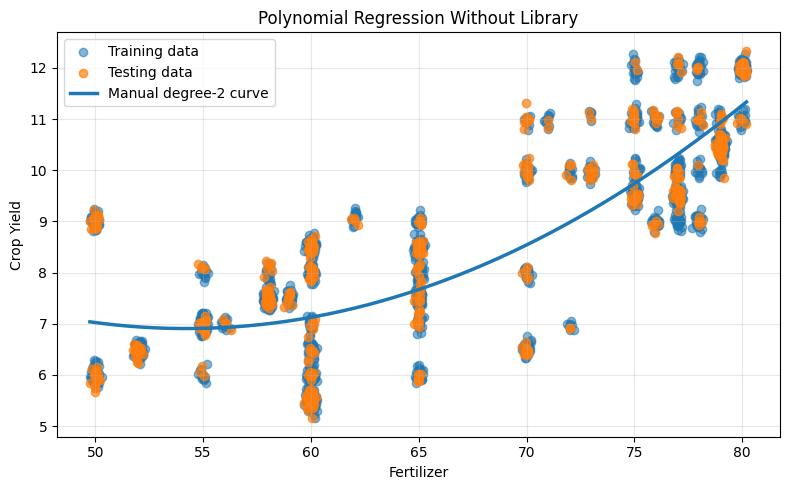

In [ ]:
x_train_poly = X_train_s[simple_feature].to_numpy(dtype=float)
x_test_poly = X_test_s[simple_feature].to_numpy(dtype=float)
y_train_poly = y_train_s.to_numpy(dtype=float)
y_test_poly = y_test_s.to_numpy(dtype=float)

# Manually create the design matrix [1, x, x^2].
A_train = np.column_stack([
    np.ones(len(x_train_poly)),
    x_train_poly,
    x_train_poly ** 2
])
A_test = np.column_stack([
    np.ones(len(x_test_poly)),
    x_test_poly,
    x_test_poly ** 2
])

coefficients_manual, *_ = np.linalg.lstsq(A_train, y_train_poly, rcond=None)
intercept_poly_manual, b1_poly_manual, b2_poly_manual = coefficients_manual
y_pred_poly_manual = A_test @ coefficients_manual

poly_manual_metrics = {
    "MSE": mean_squared_error(y_test_poly, y_pred_poly_manual),
    "RMSE": np.sqrt(mean_squared_error(y_test_poly, y_pred_poly_manual)),
    "MAE": mean_absolute_error(y_test_poly, y_pred_poly_manual),
    "R2": r2_score(y_test_poly, y_pred_poly_manual)
}

print("\nPOLYNOMIAL REGRESSION WITHOUT LIBRARY")
print("------------------------------------")
print("Intercept:", intercept_poly_manual)
print("Coefficient of x:", b1_poly_manual)
print("Coefficient of x^2:", b2_poly_manual)
for metric, value in poly_manual_metrics.items():
    print(f"{metric}: {value:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(y_test_poly, y_pred_poly_manual, alpha=0.75, label="Predictions")
low = min(y_test_poly.min(), y_pred_poly_manual.min())
high = max(y_test_poly.max(), y_pred_poly_manual.max())
plt.plot([low, high], [low, high], "--", label="Perfect prediction")
plt.xlabel("Actual Crop Yield")
plt.ylabel("Predicted Crop Yield")
plt.title("Polynomial Regression Without Library: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

x_curve_manual = np.linspace(x_train_poly.min(), x_test_poly.max(), 250)
y_curve_manual = (
    intercept_poly_manual
    + b1_poly_manual * x_curve_manual
    + b2_poly_manual * (x_curve_manual ** 2)
)

plt.figure(figsize=(8, 5))
plt.scatter(x_train_poly, y_train_poly, alpha=0.55, label="Training data")
plt.scatter(x_test_poly, y_test_poly, alpha=0.7, label="Testing data")
plt.plot(x_curve_manual, y_curve_manual, linewidth=2.5, label="Manual degree-2 curve")
plt.xlabel(simple_feature)
plt.ylabel("Crop Yield")
plt.title("Polynomial Regression Without Library")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Comparative analysis — Polynomial Regression

Polynomial Regression — Comparative Results


,Without Library,With Library
MSE,1.2234,1.2234
RMSE,1.1061,1.1061
MAE,0.9416,0.9416
R2,0.6717,0.6717


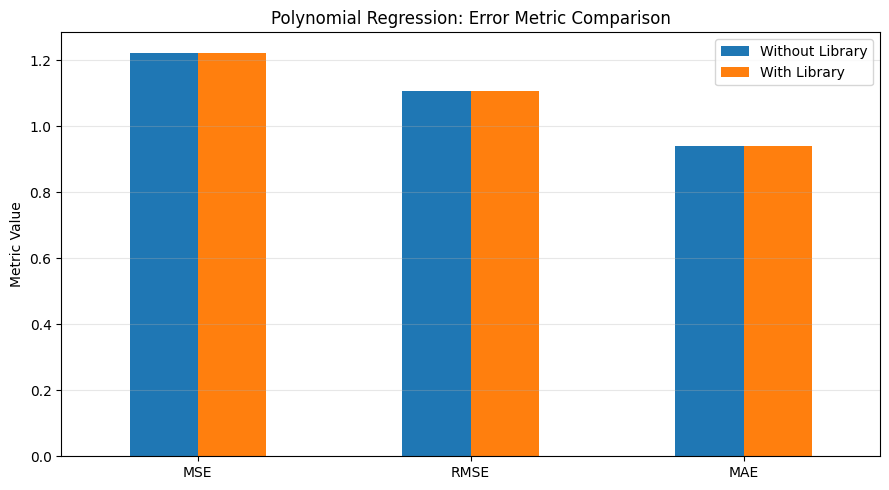

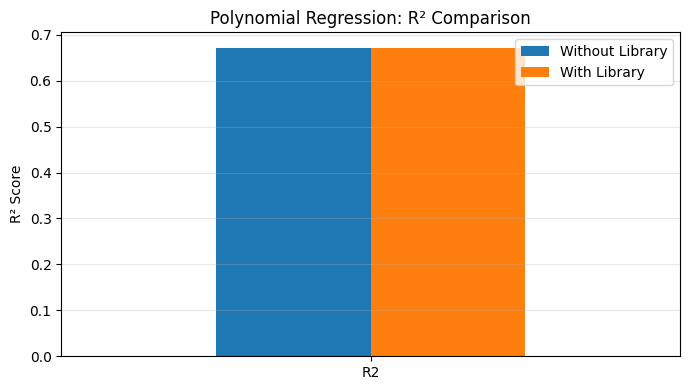

In [ ]:
poly_comparison = pd.DataFrame({
    "Without Library": poly_manual_metrics,
    "With Library": poly_lib_metrics
})
print("Polynomial Regression — Comparative Results")
display(poly_comparison.round(4))

poly_comparison.loc[["MSE", "RMSE", "MAE"]].plot(kind="bar", figsize=(9, 5))
plt.title("Polynomial Regression: Error Metric Comparison")
plt.ylabel("Metric Value")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

poly_comparison.loc[["R2"]].plot(kind="bar", figsize=(7, 4))
plt.title("Polynomial Regression: R² Comparison")
plt.ylabel("R² Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Final Model Comparison

This table compares the three model approaches using their test-set metrics. Simple and Polynomial Regression use one input feature; Multiple Linear Regression uses all available numeric input features.

FINAL MODEL COMPARISON


,MSE,RMSE,MAE,R2
Simple Linear (Library),1.4250,1.1937,0.9096,0.6176
Simple Linear (Manual),1.4250,1.1937,0.9096,0.6176
Multiple Linear (Library),0.4784,0.6917,0.5720,0.8716
Multiple Linear (Gradient Descent),0.4784,0.6917,0.5720,0.8716
Polynomial (Library),1.2234,1.1061,0.9416,0.6717
Polynomial (Manual),1.2234,1.1061,0.9416,0.6717



Lowest test RMSE:
Multiple Linear (Library) -> 0.6917

Highest test R²:
Multiple Linear (Library) -> 0.8716


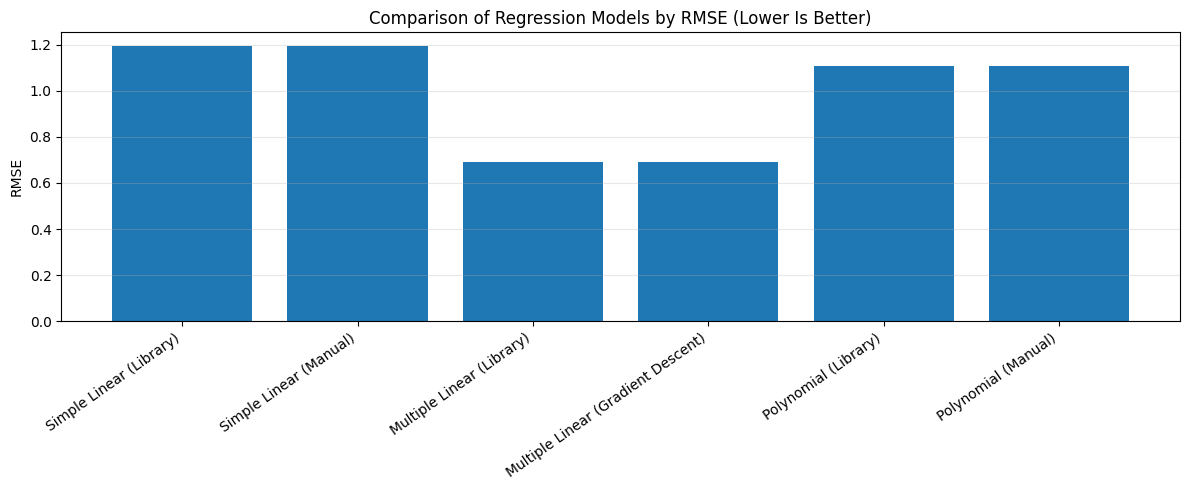

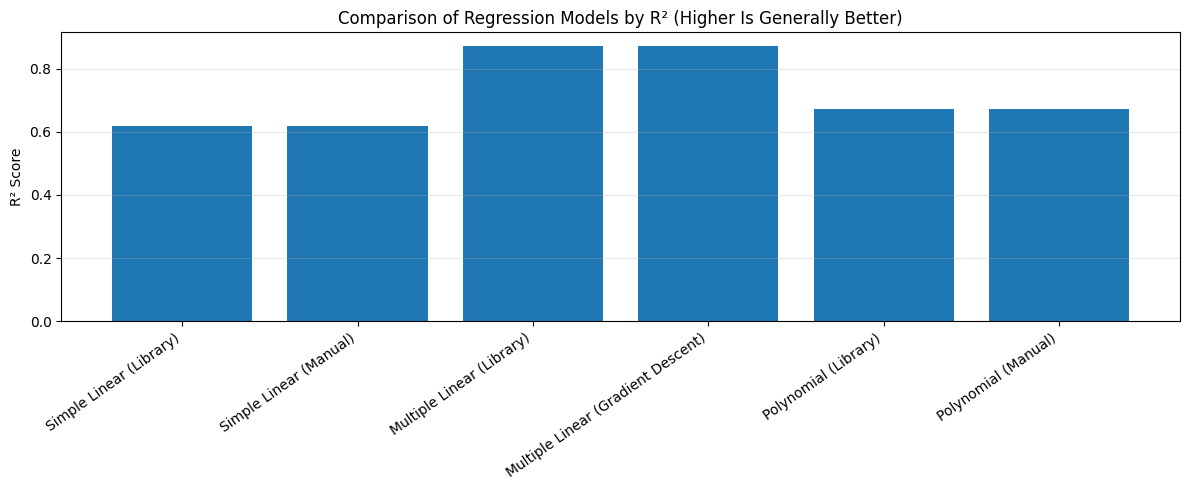

In [ ]:
all_results = pd.DataFrame({
    "Simple Linear (Library)": simple_lib_metrics,
    "Simple Linear (Manual)": simple_manual_metrics,
    "Multiple Linear (Library)": multi_lib_metrics,
    "Multiple Linear (Gradient Descent)": multi_gd_metrics,
    "Polynomial (Library)": poly_lib_metrics,
    "Polynomial (Manual)": poly_manual_metrics
}).T

print("FINAL MODEL COMPARISON")
display(all_results.round(4))

print("\nLowest test RMSE:")
print(all_results["RMSE"].idxmin(), "->", round(all_results["RMSE"].min(), 4))

print("\nHighest test R²:")
print(all_results["R2"].idxmax(), "->", round(all_results["R2"].max(), 4))

# Plot RMSE comparison
plt.figure(figsize=(12, 5))
plt.bar(all_results.index, all_results["RMSE"])
plt.ylabel("RMSE")
plt.title("Comparison of Regression Models by RMSE (Lower Is Better)")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Plot R² comparison
plt.figure(figsize=(12, 5))
plt.bar(all_results.index, all_results["R2"])
plt.ylabel("R² Score")
plt.title("Comparison of Regression Models by R² (Higher Is Generally Better)")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Conclusion

In this practical, regression models were developed for the real-world task of crop-yield prediction. The dataset was explored and cleaned, and plots were used to inspect the distributions and relationships among agricultural features.

Simple Linear Regression was implemented using scikit-learn and manually using the least-squares formulas. Multiple Linear Regression was implemented using scikit-learn and from scratch using Gradient Descent. Polynomial Regression was implemented using scikit-learn and manually by constructing degree-2 features.

The models were evaluated using MSE, RMSE, MAE, and R². Use the actual metric values produced by your notebook to state which model performed best. A lower RMSE/MAE indicates smaller prediction errors, while a higher R² generally indicates that the model explains more variation in crop yield. Gradient Descent's cost plot can be used to inspect whether training cost decreases over iterations.

**Reflection:** This experiment demonstrates how regression can support agricultural planning by estimating crop yield from soil and weather-related measurements. Model quality depends on the dataset, the selected features, and the representativeness of the data. Predictions should be treated as estimates, not guarantees of actual farm production.